# Data Preprocessing

#### Data Cleaning

In [71]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [100]:
df = pd.read_csv("F:/DataSets for Artificial Intelligence/greenko assignment/02_renewable_asset_fault_anomaly_copilot/data/asset_telemetry.csv")

In [73]:
print(df.shape)
df.columns

(240, 8)


Index(['timestamp_id', 'asset_id', 'hour', 'irradiance_wm2', 'wind_speed_ms',
       'temperature_c', 'vibration_mm_s', 'power_mw'],
      dtype='object')

In [74]:
df.iloc[:5]

,timestamp_id,asset_id,hour,irradiance_wm2,wind_speed_ms,temperature_c,vibration_mm_s,power_mw
0,0,SOLAR_INV_01,0,0.0,6.57,26.26,1.37,0.0
1,1,SOLAR_INV_01,1,0.0,6.72,24.89,1.49,0.0
2,2,SOLAR_INV_01,2,0.0,6.26,23.85,1.25,0.0
3,3,SOLAR_INV_01,3,0.0,7.24,24.45,1.29,0.0
4,4,SOLAR_INV_01,4,0.0,7.39,26.45,1.50,0.0


In [75]:
df.describe()

,timestamp_id,hour,irradiance_wm2,wind_speed_ms,temperature_c,vibration_mm_s,power_mw
count,240.00000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000
mean,119.50000,11.500000,126.595833,6.069333,32.312292,1.400667,0.875367
std,69.42622,6.936653,253.453792,1.581222,6.345355,0.365517,0.753791
min,0.00000,0.000000,0.000000,3.160000,22.350000,1.200000,0.000000
25%,59.75000,5.750000,0.000000,4.710000,26.267500,1.270000,0.000000
50%,119.50000,11.500000,0.000000,6.200000,32.285000,1.360000,0.760000
75%,179.25000,17.250000,0.000000,7.400000,37.977500,1.430000,1.468000
max,239.00000,23.000000,800.000000,8.990000,53.480000,3.980000,2.618000


In [76]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   timestamp_id    240 non-null    int64  
 1   asset_id        240 non-null    object 
 2   hour            240 non-null    int64  
 3   irradiance_wm2  240 non-null    float64
 4   wind_speed_ms   240 non-null    float64
 5   temperature_c   240 non-null    float64
 6   vibration_mm_s  240 non-null    float64
 7   power_mw        240 non-null    float64
dtypes: float64(5), int64(2), object(1)
memory usage: 15.1+ KB


In [24]:
# Check data types
print(df.dtypes)

timestamp_id        int64
asset_id           object
hour                int64
irradiance_wm2    float64
wind_speed_ms     float64
temperature_c     float64
vibration_mm_s    float64
power_mw          float64
asset_type         object
dtype: object


In [ ]:
# Data Cleaning 

In [77]:
df.isnull().sum()

timestamp_id      0
asset_id          0
hour              0
irradiance_wm2    0
wind_speed_ms     0
temperature_c     0
vibration_mm_s    0
power_mw          0
dtype: int64

In [79]:
df[df.duplicated()]

,timestamp_id,asset_id,hour,irradiance_wm2,wind_speed_ms,temperature_c,vibration_mm_s,power_mw


In [78]:
df['timestamp_id'].duplicated().sum()

0

In [80]:
df['irradiance_wm2'].unique()

array([  0. , 207.1, 400. , 565.7, 692.8, 772.7, 800. ])

In [30]:
# df['wind_speed_ms'].unique()

In [81]:
# Check for Negative values
numeric_cols = [
    'hour', 'irradiance_wm2', 'wind_speed_ms',
    'temperature_c', 'vibration_mm_s', 'power_mw'
]

for col in numeric_cols:
    print(f"\n{col}")
    print("Non-numeric values:", pd.to_numeric(df[col], errors='coerce').isna().sum() - df[col].isna().sum())
    print("Negative values:", (df[col] < 0).sum())


hour
Non-numeric values: 0
Negative values: 0

irradiance_wm2
Non-numeric values: 0
Negative values: 0

wind_speed_ms
Non-numeric values: 0
Negative values: 0

temperature_c
Non-numeric values: 0
Negative values: 0

vibration_mm_s
Non-numeric values: 0
Negative values: 0

power_mw
Non-numeric values: 0
Negative values: 0


In [82]:
# Checking for duplicate asset-observation pairs
duplicate_observations = df[
    df.duplicated(subset=['asset_id', 'timestamp_id'], keep=False)
].sort_values(['asset_id', 'timestamp_id'])

print("Duplicate asset-observation pairs:")
display(duplicate_observations)

# Check whether duplicate pairs have conflicting readings
print("Number of conflicting asset-observation pairs:")

conflicts = (
    duplicate_observations
    .groupby(['asset_id', 'timestamp_id'])[numeric_cols]
    .nunique()
    .gt(1)
    .any(axis=1)
)

print(conflicts.sum())

Duplicate asset-observation pairs:


,timestamp_id,asset_id,hour,irradiance_wm2,wind_speed_ms,temperature_c,vibration_mm_s,power_mw


Number of conflicting asset-observation pairs:
0


In [10]:
# Feature Engg

In [83]:
df.loc[:10]

,timestamp_id,asset_id,hour,irradiance_wm2,wind_speed_ms,temperature_c,vibration_mm_s,power_mw
0,0,SOLAR_INV_01,0,0.0,6.57,26.26,1.37,0.000
1,1,SOLAR_INV_01,1,0.0,6.72,24.89,1.49,0.000
2,2,SOLAR_INV_01,2,0.0,6.26,23.85,1.25,0.000
3,3,SOLAR_INV_01,3,0.0,7.24,24.45,1.29,0.000
4,4,SOLAR_INV_01,4,0.0,7.39,26.45,1.50,0.000
5,5,SOLAR_INV_01,5,0.0,7.39,28.05,1.46,0.000
6,6,SOLAR_INV_01,6,0.0,7.87,28.77,1.22,0.000
7,7,SOLAR_INV_01,7,207.1,8.00,31.85,1.33,0.393
8,8,SOLAR_INV_01,8,400.0,6.99,31.52,1.27,0.760
9,9,SOLAR_INV_01,9,565.7,8.64,32.22,1.43,1.075


In [84]:
df[df['asset_id'] == 'WTG_07']

,timestamp_id,asset_id,hour,irradiance_wm2,wind_speed_ms,temperature_c,vibration_mm_s,power_mw
120,120,WTG_07,0,0.0,6.32,24.82,1.24,1.496
121,121,WTG_07,1,0.0,7.30,22.35,1.41,1.934
122,122,WTG_07,2,0.0,7.59,24.80,1.21,2.066
123,123,WTG_07,3,0.0,6.60,22.96,1.41,1.620
124,124,WTG_07,4,0.0,5.52,24.44,1.32,1.133
...,...,...,...,...,...,...,...,...
235,235,WTG_07,19,0.0,3.65,32.44,1.21,0.292
236,236,WTG_07,20,0.0,4.59,33.24,1.36,0.716
237,237,WTG_07,21,0.0,3.29,30.10,1.22,0.129
238,238,WTG_07,22,0.0,3.17,29.00,1.46,0.077


# Exploratory Data Analysis

In [85]:
asset_id = df["asset_id"].astype("string").str.upper()

df["asset_type"] = np.select(
    [
        asset_id.str.startswith("SOLAR", na=False),
        asset_id.str.startswith("WTG", na=False),
    ],
    [
        "solar",
        "wind",
    ],
    default="unknown",
)

In [86]:
# df
df.iloc[:5]

,timestamp_id,asset_id,hour,irradiance_wm2,wind_speed_ms,temperature_c,vibration_mm_s,power_mw,asset_type
0,0,SOLAR_INV_01,0,0.0,6.57,26.26,1.37,0.0,solar
1,1,SOLAR_INV_01,1,0.0,6.72,24.89,1.49,0.0,solar
2,2,SOLAR_INV_01,2,0.0,6.26,23.85,1.25,0.0,solar
3,3,SOLAR_INV_01,3,0.0,7.24,24.45,1.29,0.0,solar
4,4,SOLAR_INV_01,4,0.0,7.39,26.45,1.50,0.0,solar


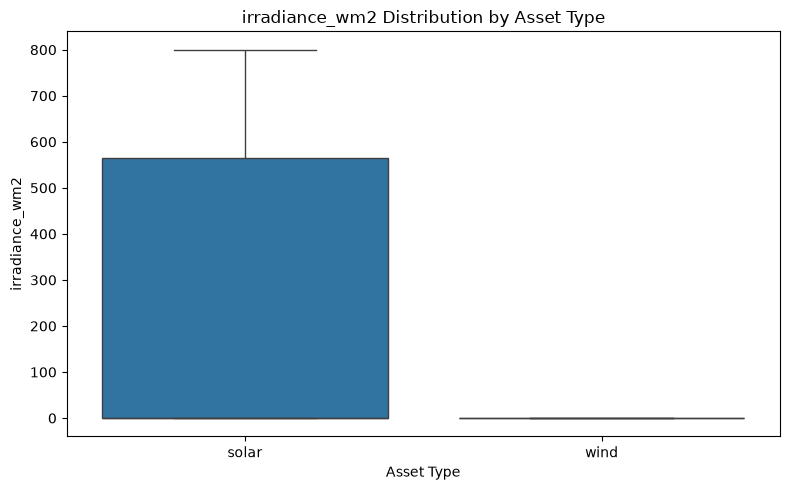

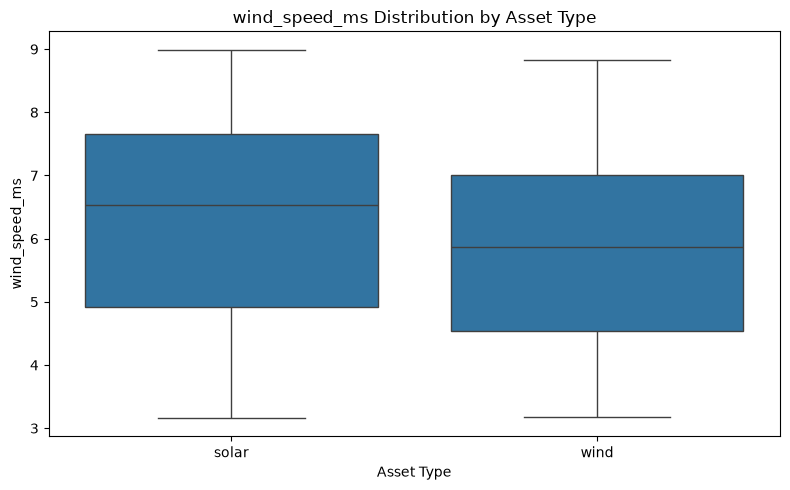

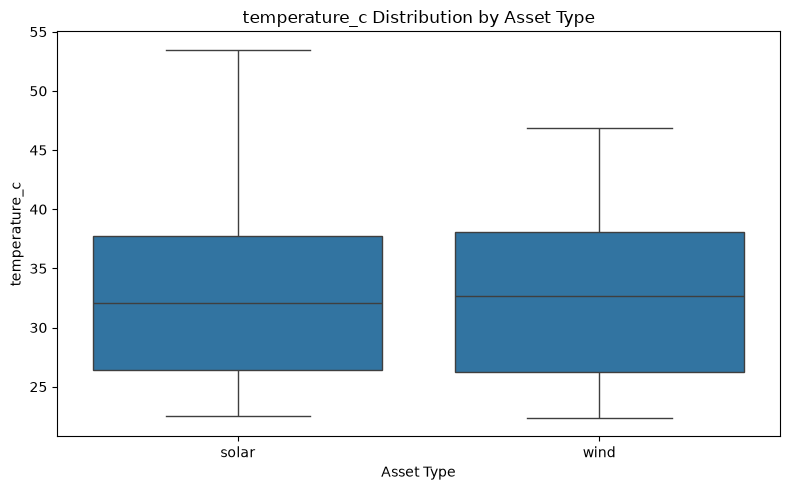

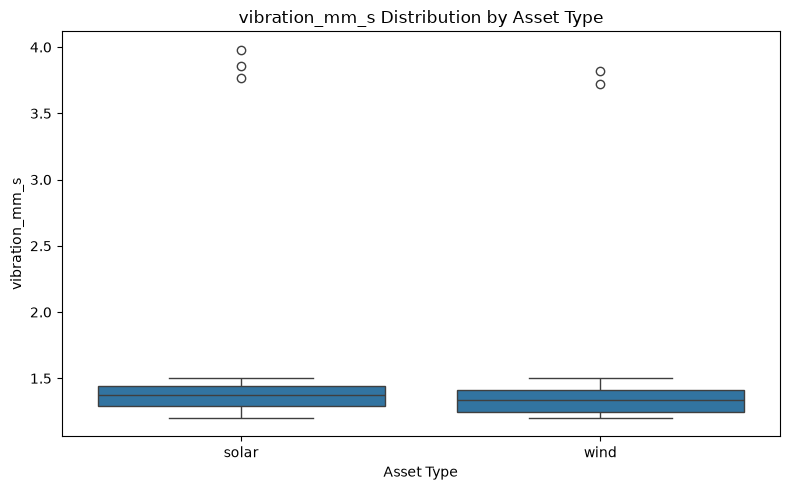

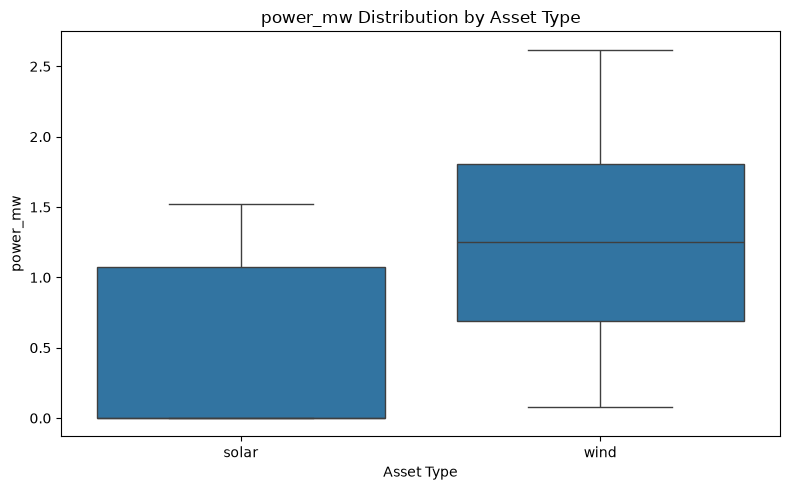

In [40]:
# Numerical columns to analyse
columns = [
    'irradiance_wm2',
    'wind_speed_ms',
    'temperature_c',
    'vibration_mm_s',
    'power_mw'
]

# Plot distributions separately for each asset type
for col in columns:
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x='asset_type',
        y=col
    )

    plt.title(f'{col} Distribution by Asset Type')
    plt.xlabel('Asset Type')
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

Observations -
1. Outliers are present in vibration_mm_s for both asset types
2. The 'irradiance' values for all the 'wind' assets are 0
3. The median value of 'irradiance' is 0

In [55]:
# Scatter plot for relationship betweeen irradiance and power_mw

# solar_df = df[df['asset_type'] == 'Solar']

# plt.figure(figsize=(8, 5))

# sns.scatterplot(
#     data=solar_df,
#     x='irradiance_wm2',
#     y='power_mw'
# )

# plt.title('Solar Power vs Irradiance')
# plt.xlabel('Irradiance (W/m²)')
# plt.ylabel('Power (MW)')
# plt.tight_layout()
# plt.show()

In [53]:
solar_df = df[df['asset_type'].str.lower() == 'solar']

print("Solar rows:", len(solar_df))
print(solar_df[['irradiance_wm2', 'power_mw']].describe())
print(solar_df[['irradiance_wm2', 'power_mw']].head())

Solar rows: 120
       irradiance_wm2    power_mw
count      120.000000  120.000000
mean       253.191667    0.481000
std        310.958371    0.590785
min          0.000000    0.000000
25%          0.000000    0.000000
50%          0.000000    0.000000
75%        565.700000    1.075000
max        800.000000    1.520000
   irradiance_wm2  power_mw
0             0.0       0.0
1             0.0       0.0
2             0.0       0.0
3             0.0       0.0
4             0.0       0.0


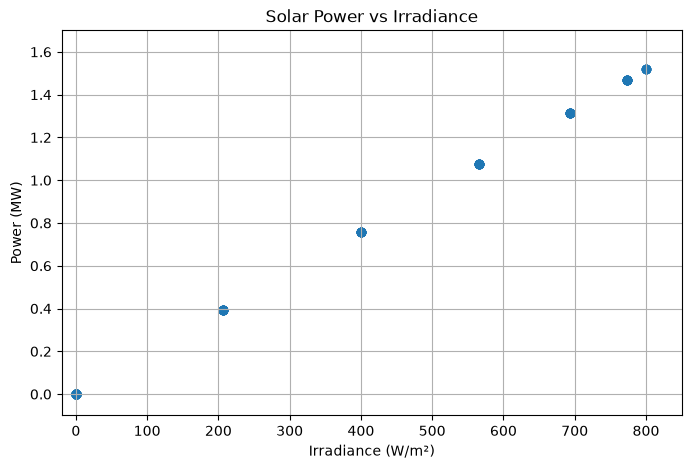

In [54]:
plt.figure(figsize=(8, 5))

plt.scatter(solar_df['irradiance_wm2'], solar_df['power_mw'])
plt.xlabel('Irradiance (W/m²)')
plt.ylabel('Power (MW)')
plt.title('Solar Power vs Irradiance')
plt.xlim(-20, 850)
plt.ylim(-0.1, 1.7)
plt.grid(True)
plt.show()

Observations -
1. Positive relationship: The plot appears to show that as irradiance increases, solar power generation generally increases.

2. Anomaly detection implication: Solar power that is unexpectedly low under high irradiance could indicate a potential anomaly, but this needs to be checked against the actual data and operating conditions.


In [ ]:
# Plot Between the Wind Speed and Power generated

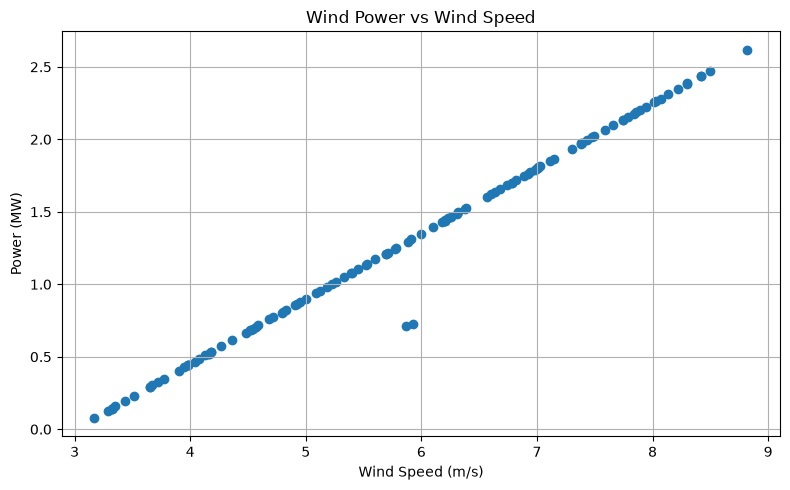

In [56]:
wind_df = df[df['asset_type'].str.lower() == 'wind']

plt.figure(figsize=(8, 5))

plt.scatter(
    wind_df['wind_speed_ms'],
    wind_df['power_mw']
)

plt.xlabel('Wind Speed (m/s)')
plt.ylabel('Power (MW)')
plt.title('Wind Power vs Wind Speed')

plt.grid(True)
plt.tight_layout()
plt.show()

Observations - 
1. The plot shows linear relationship, (straight line) between the features
2. Power generation is lower than expected for the observed wind speeds, compared with the other points can be potential analomy

In [58]:
# Correlation heatmaps for Numerical features for both the assets


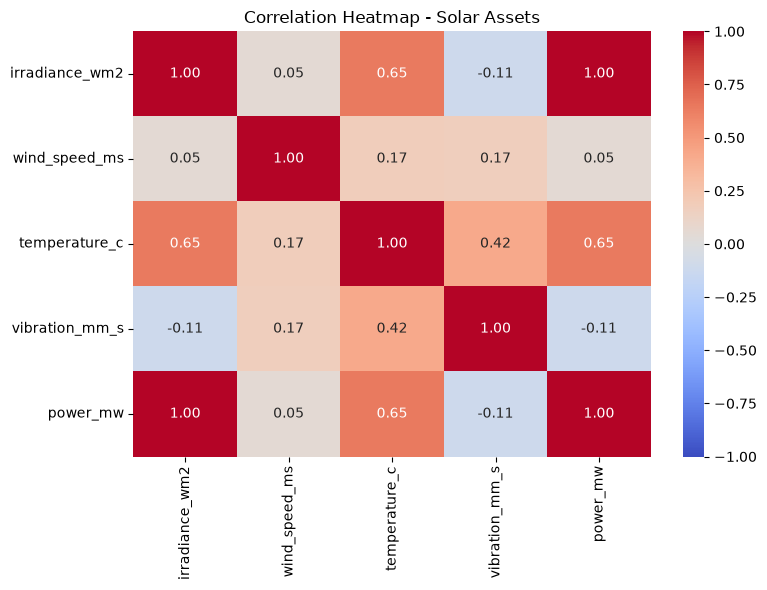

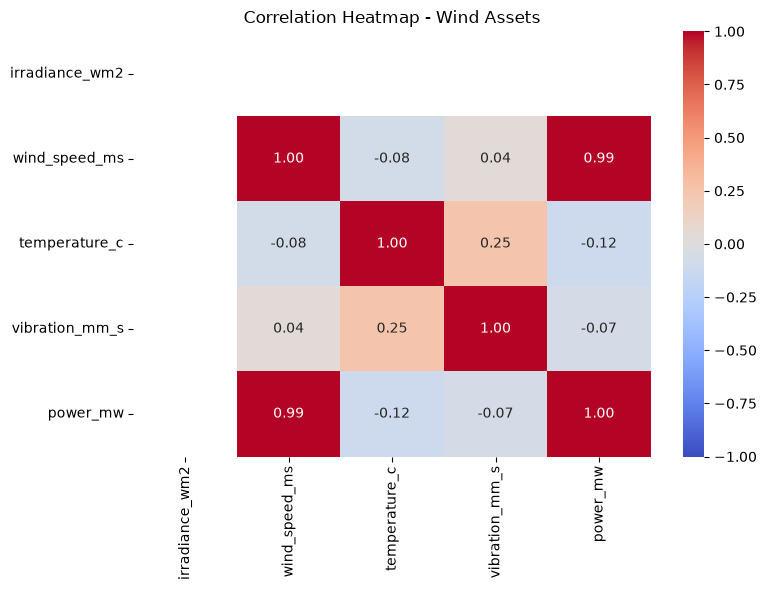

In [59]:
# Select numerical columns
numerical_columns = [
    'irradiance_wm2',
    'wind_speed_ms',
    'temperature_c',
    'vibration_mm_s',
    'power_mw'
]

# Separate solar and wind data
solar_df = df[df['asset_type'].str.lower() == 'solar']
wind_df = df[df['asset_type'].str.lower() == 'wind']

# Solar correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    solar_df[numerical_columns].corr(),
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt='.2f'
)
plt.title('Correlation Heatmap - Solar Assets')
plt.tight_layout()
plt.show()

# Wind correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    wind_df[numerical_columns].corr(),
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt='.2f'
)
plt.title('Correlation Heatmap - Wind Assets')
plt.tight_layout()
plt.show()

In [ ]:
# Scatter plot of Vibrations with 

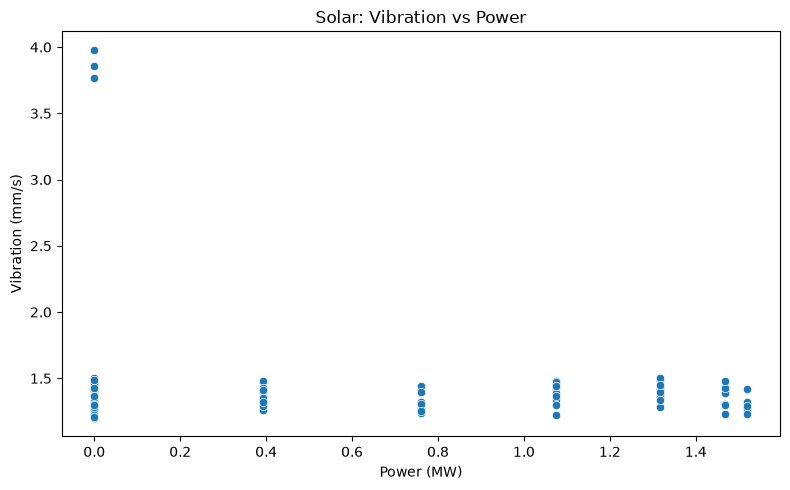

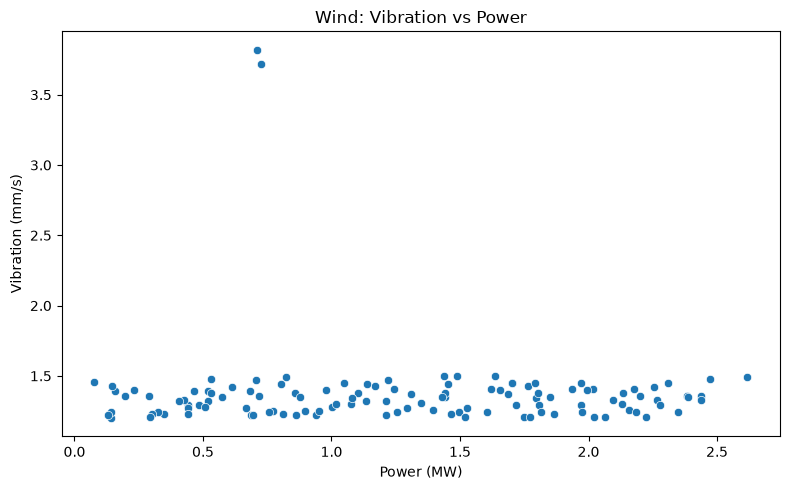

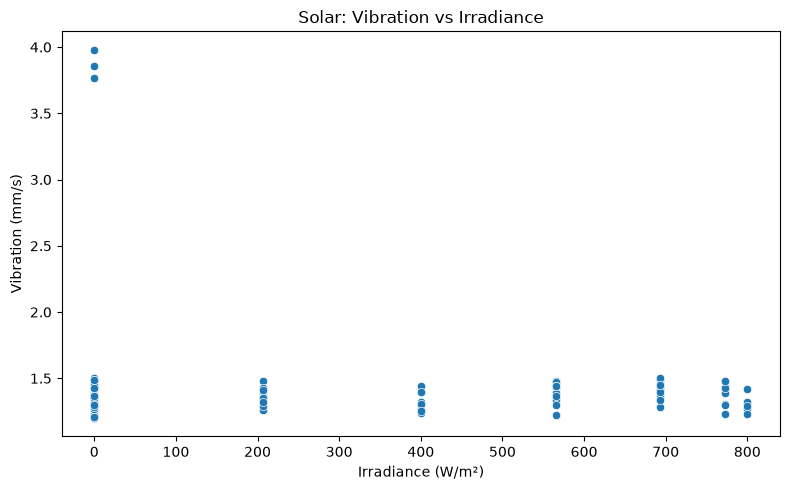

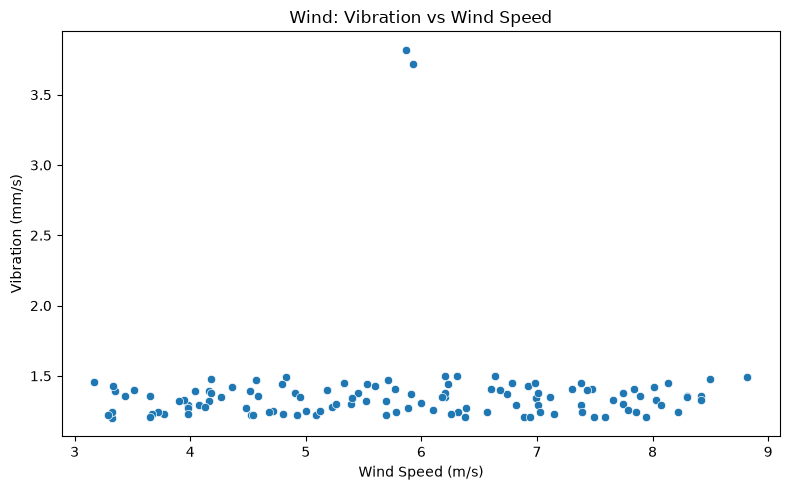

In [60]:
solar_df = df[df['asset_type'].str.lower() == 'solar']
wind_df = df[df['asset_type'].str.lower() == 'wind']

# 1. Vibration vs Power — Solar
plt.figure(figsize=(8, 5))
sns.scatterplot(data=solar_df, x='power_mw', y='vibration_mm_s')
plt.title('Solar: Vibration vs Power')
plt.xlabel('Power (MW)')
plt.ylabel('Vibration (mm/s)')
plt.tight_layout()
plt.show()

# 2. Vibration vs Power — Wind
plt.figure(figsize=(8, 5))
sns.scatterplot(data=wind_df, x='power_mw', y='vibration_mm_s')
plt.title('Wind: Vibration vs Power')
plt.xlabel('Power (MW)')
plt.ylabel('Vibration (mm/s)')
plt.tight_layout()
plt.show()

# 3. Vibration vs Operating Conditions — Solar
plt.figure(figsize=(8, 5))
sns.scatterplot(data=solar_df, x='irradiance_wm2', y='vibration_mm_s')
plt.title('Solar: Vibration vs Irradiance')
plt.xlabel('Irradiance (W/m²)')
plt.ylabel('Vibration (mm/s)')
plt.tight_layout()
plt.show()

# 4. Vibration vs Operating Conditions — Wind
plt.figure(figsize=(8, 5))
sns.scatterplot(data=wind_df, x='wind_speed_ms', y='vibration_mm_s')
plt.title('Wind: Vibration vs Wind Speed')
plt.xlabel('Wind Speed (m/s)')
plt.ylabel('Vibration (mm/s)')
plt.tight_layout()
plt.show()

Observation-
Solar: Vibration is mostly below 1.5 mm/s, but some readings exceed 3.5 mm/s at zero power.

Wind: Vibration is mostly below 1.5 mm/s, with two readings above 3.5 mm/s at 0.5–1.0 MW and around 6 m/s wind speed.

Implication: Will Investigate high-vibration readings under asset-specific operating conditions as potential anomalies.

# Feature Engineering

In [ ]:
# Prepartion of data for time series Analysis

In [87]:
df.columns

Index(['timestamp_id', 'asset_id', 'hour', 'irradiance_wm2', 'wind_speed_ms',
       'temperature_c', 'vibration_mm_s', 'power_mw', 'asset_type'],
      dtype='object')

In [98]:
engg_df = df.copy()

In [94]:
# Conversion of  timestamps to datetime
df["timestamp_id"] = pd.to_datetime(df["timestamp_id"], errors="coerce")

# Checking of  invalid timestamps
invalid_timestamps = df["timestamp_id"].isna().sum()
print("Invalid timestamps:", invalid_timestamps)

# Removal of  rows with invalid timestamps
df = df.dropna(subset=["timestamp_id"])

# Sorting readings by asset and timestamp
df = df.sort_values(
    by=["asset_id", "timestamp_id"]
).reset_index(drop=True)

print("Data shape:", df.shape)
print("Assets:", df["asset_id"].nunique())
print("Timestamp range:", df["timestamp_id"].min(), "to", df["timestamp_id"].max())

Invalid timestamps: 0
Data shape: (240, 9)
Assets: 2
Timestamp range: 1970-01-01 00:00:00 to 1970-01-01 00:00:00.000000239


In [68]:
# Encoding the daily operating cycle in hours

In [95]:
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

In [103]:
engg_df.iloc[:5]

,timestamp_id,asset_id,hour,irradiance_wm2,wind_speed_ms,temperature_c,vibration_mm_s,power_mw,asset_type,hour_sin,hour_cos
0,1970-01-01 00:00:00.000000000,SOLAR_INV_01,0,0.0,6.57,26.26,1.37,0.0,solar,0.000000,1.000000
1,1970-01-01 00:00:00.000000001,SOLAR_INV_01,1,0.0,6.72,24.89,1.49,0.0,solar,0.258819,0.965926
2,1970-01-01 00:00:00.000000002,SOLAR_INV_01,2,0.0,6.26,23.85,1.25,0.0,solar,0.500000,0.866025
3,1970-01-01 00:00:00.000000003,SOLAR_INV_01,3,0.0,7.24,24.45,1.29,0.0,solar,0.707107,0.707107
4,1970-01-01 00:00:00.000000004,SOLAR_INV_01,4,0.0,7.39,26.45,1.50,0.0,solar,0.866025,0.500000


In [104]:
engg_df = engg_df.drop(columns=["hour"])

In [105]:
engg_df.iloc[:5]

,timestamp_id,asset_id,irradiance_wm2,wind_speed_ms,temperature_c,vibration_mm_s,power_mw,asset_type,hour_sin,hour_cos
0,1970-01-01 00:00:00.000000000,SOLAR_INV_01,0.0,6.57,26.26,1.37,0.0,solar,0.000000,1.000000
1,1970-01-01 00:00:00.000000001,SOLAR_INV_01,0.0,6.72,24.89,1.49,0.0,solar,0.258819,0.965926
2,1970-01-01 00:00:00.000000002,SOLAR_INV_01,0.0,6.26,23.85,1.25,0.0,solar,0.500000,0.866025
3,1970-01-01 00:00:00.000000003,SOLAR_INV_01,0.0,7.24,24.45,1.29,0.0,solar,0.707107,0.707107
4,1970-01-01 00:00:00.000000004,SOLAR_INV_01,0.0,7.39,26.45,1.50,0.0,solar,0.866025,0.500000


In [ ]:
# Initialize operating-context features

In [106]:
engg_df["solar_power_per_irradiance"] = np.nan
engg_df["wind_power_per_speed"] = np.nan

# Solar operating context: only where irradiance is positive
solar_mask = (
    engg_df["asset_type"].str.lower().eq("solar")
    & engg_df["irradiance_wm2"].gt(0)
    & engg_df["power_mw"].ge(0)
)

engg_df.loc[solar_mask, "solar_power_per_irradiance"] = (
    engg_df.loc[solar_mask, "power_mw"]
    / engg_df.loc[solar_mask, "irradiance_wm2"]
)

# Wind operating context: only where wind speed is positive
wind_mask = (
    engg_df["asset_type"].str.lower().eq("wind")
    & engg_df["wind_speed_ms"].gt(0)
    & engg_df["power_mw"].ge(0)
)

engg_df.loc[wind_mask, "wind_power_per_speed"] = (
    engg_df.loc[wind_mask, "power_mw"]
    / engg_df.loc[wind_mask, "wind_speed_ms"]
)

In [108]:
engg_df[:5]

,timestamp_id,asset_id,irradiance_wm2,wind_speed_ms,temperature_c,vibration_mm_s,power_mw,asset_type,hour_sin,hour_cos,solar_power_per_irradiance,wind_power_per_speed
0,1970-01-01 00:00:00.000000000,SOLAR_INV_01,0.0,6.57,26.26,1.37,0.0,solar,0.000000,1.000000,NaN,NaN
1,1970-01-01 00:00:00.000000001,SOLAR_INV_01,0.0,6.72,24.89,1.49,0.0,solar,0.258819,0.965926,NaN,NaN
2,1970-01-01 00:00:00.000000002,SOLAR_INV_01,0.0,6.26,23.85,1.25,0.0,solar,0.500000,0.866025,NaN,NaN
3,1970-01-01 00:00:00.000000003,SOLAR_INV_01,0.0,7.24,24.45,1.29,0.0,solar,0.707107,0.707107,NaN,NaN
4,1970-01-01 00:00:00.000000004,SOLAR_INV_01,0.0,7.39,26.45,1.50,0.0,solar,0.866025,0.500000,NaN,NaN


In [109]:
engg_df['solar_power_per_irradiance'].unique()

array([       nan, 0.00189763, 0.0019    , 0.0019003 , 0.00189954,
       0.00189983])

In [111]:
# engg_df['wind_power_per_speed'].unique()

#### Measurements for rolling anomaly detection

In [ ]:
columns_to_monitor = [
    "power_mw",
    "vibration_mm_s",
    "irradiance_wm2",
    "wind_speed_ms"
]

window = 6
min_periods = 3

# Calculate rolling features separately for each asset
for col in columns_to_monitor:

    # Historical rolling median
    engg_df[f"{col}_rolling_median"] = (
        engg_df.groupby("asset_id")[col]
        .transform(
            lambda s: s.shift(1).rolling(
                window=window,
                min_periods=min_periods
            ).median()
        )
    )

    # Historical rolling MAD
    engg_df[f"{col}_rolling_mad"] = (
        engg_df.groupby("asset_id")[col]
        .transform(
            lambda s: s.shift(1).rolling(
                window=window,
                min_periods=min_periods
            ).apply(
                lambda x: np.median(
                    np.abs(x - np.median(x))
                ),
                raw=True
            )
        )
    )

    # Modified Z-score
    engg_df[f"{col}_modified_zscore"] = (
        0.6745
        * (
            engg_df[col]
            - engg_df[f"{col}_rolling_median"]
        )
        / engg_df[f"{col}_rolling_mad"].replace(0, np.nan)
    )

# Verify generated features
rolling_features = [
    col for col in engg_df.columns
    if any(
        suffix in col
        for suffix in [
            "_rolling_median",
            "_rolling_mad",
            "_modified_zscore"
        ]
    )
]

print("Rolling features created:", len(rolling_features))
print(engg_df[rolling_features].head())

Rolling features created: 12
   power_mw_rolling_median  power_mw_rolling_mad  power_mw_modified_zscore  \
0                      NaN                   NaN                       NaN   
1                      NaN                   NaN                       NaN   
2                      NaN                   NaN                       NaN   
3                      0.0                   NaN                       NaN   
4                      0.0                   NaN                       NaN   

   vibration_mm_s_rolling_median  vibration_mm_s_rolling_mad  \
0                            NaN                         NaN   
1                            NaN                         NaN   
2                            NaN                         NaN   
3                           1.37                         NaN   
4                           1.33                         NaN   

   vibration_mm_s_modified_zscore  irradiance_wm2_rolling_median  \
0                             NaN                

In [114]:
engg_df.iloc[:5]

,timestamp_id,asset_id,irradiance_wm2,wind_speed_ms,temperature_c,vibration_mm_s,power_mw,asset_type,hour_sin,hour_cos,...,power_mw_modified_zscore,vibration_mm_s_rolling_median,vibration_mm_s_rolling_mad,vibration_mm_s_modified_zscore,irradiance_wm2_rolling_median,irradiance_wm2_rolling_mad,irradiance_wm2_modified_zscore,wind_speed_ms_rolling_median,wind_speed_ms_rolling_mad,wind_speed_ms_modified_zscore
0,1970-01-01 00:00:00.000000000,SOLAR_INV_01,0.0,6.57,26.26,1.37,0.0,solar,0.000000,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1970-01-01 00:00:00.000000001,SOLAR_INV_01,0.0,6.72,24.89,1.49,0.0,solar,0.258819,0.965926,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1970-01-01 00:00:00.000000002,SOLAR_INV_01,0.0,6.26,23.85,1.25,0.0,solar,0.500000,0.866025,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1970-01-01 00:00:00.000000003,SOLAR_INV_01,0.0,7.24,24.45,1.29,0.0,solar,0.707107,0.707107,...,NaN,1.37,NaN,NaN,0.0,NaN,NaN,6.570,NaN,NaN
4,1970-01-01 00:00:00.000000004,SOLAR_INV_01,0.0,7.39,26.45,1.50,0.0,solar,0.866025,0.500000,...,NaN,1.33,NaN,NaN,0.0,NaN,NaN,6.645,NaN,NaN


In [115]:
engg_df.shape

(240, 24)

In [116]:
engg_df.columns

Index(['timestamp_id', 'asset_id', 'irradiance_wm2', 'wind_speed_ms',
       'temperature_c', 'vibration_mm_s', 'power_mw', 'asset_type', 'hour_sin',
       'hour_cos', 'solar_power_per_irradiance', 'wind_power_per_speed',
       'power_mw_rolling_median', 'power_mw_rolling_mad',
       'power_mw_modified_zscore', 'vibration_mm_s_rolling_median',
       'vibration_mm_s_rolling_mad', 'vibration_mm_s_modified_zscore',
       'irradiance_wm2_rolling_median', 'irradiance_wm2_rolling_mad',
       'irradiance_wm2_modified_zscore', 'wind_speed_ms_rolling_median',
       'wind_speed_ms_rolling_mad', 'wind_speed_ms_modified_zscore'],
      dtype='object')

In [ ]:
# Calculate power change between consecutive readings per asset as 'power_change

In [118]:
engg_df["power_change_mw"] = (
    engg_df.groupby("asset_id")["power_mw"].diff()
)

In [120]:
engg_df.iloc[:2]

,timestamp_id,asset_id,irradiance_wm2,wind_speed_ms,temperature_c,vibration_mm_s,power_mw,asset_type,hour_sin,hour_cos,...,vibration_mm_s_rolling_median,vibration_mm_s_rolling_mad,vibration_mm_s_modified_zscore,irradiance_wm2_rolling_median,irradiance_wm2_rolling_mad,irradiance_wm2_modified_zscore,wind_speed_ms_rolling_median,wind_speed_ms_rolling_mad,wind_speed_ms_modified_zscore,power_change_mw
0,1970-01-01 00:00:00.000000000,SOLAR_INV_01,0.0,6.57,26.26,1.37,0.0,solar,0.000000,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1970-01-01 00:00:00.000000001,SOLAR_INV_01,0.0,6.72,24.89,1.49,0.0,solar,0.258819,0.965926,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0


In [121]:
engg_df.columns

Index(['timestamp_id', 'asset_id', 'irradiance_wm2', 'wind_speed_ms',
       'temperature_c', 'vibration_mm_s', 'power_mw', 'asset_type', 'hour_sin',
       'hour_cos', 'solar_power_per_irradiance', 'wind_power_per_speed',
       'power_mw_rolling_median', 'power_mw_rolling_mad',
       'power_mw_modified_zscore', 'vibration_mm_s_rolling_median',
       'vibration_mm_s_rolling_mad', 'vibration_mm_s_modified_zscore',
       'irradiance_wm2_rolling_median', 'irradiance_wm2_rolling_mad',
       'irradiance_wm2_modified_zscore', 'wind_speed_ms_rolling_median',
       'wind_speed_ms_rolling_mad', 'wind_speed_ms_modified_zscore',
       'power_change_mw'],
      dtype='object')

In [126]:
# Removing the "solar_power_per_irradiance", "wind_power_per_speed" columns

In [ ]:
engg_df = engg_df.drop(
    columns=[
        "solar_power_per_irradiance",
        "wind_power_per_speed"
    ]
)

In [128]:
engg_df.shape

(240, 23)

In [129]:
engg_df.isnull().sum()

timestamp_id                        0
asset_id                            0
irradiance_wm2                      0
wind_speed_ms                       0
temperature_c                       0
vibration_mm_s                      0
power_mw                            0
asset_type                          0
hour_sin                            0
hour_cos                            0
power_mw_rolling_median             6
power_mw_rolling_mad               12
power_mw_modified_zscore           66
vibration_mm_s_rolling_median       6
vibration_mm_s_rolling_mad         12
vibration_mm_s_modified_zscore     12
irradiance_wm2_rolling_median       6
irradiance_wm2_rolling_mad         12
irradiance_wm2_modified_zscore    180
wind_speed_ms_rolling_median        6
wind_speed_ms_rolling_mad          12
wind_speed_ms_modified_zscore      12
power_change_mw                     2
dtype: int64

In [130]:
# Investigation on why modified Z-scores are missing

for col in [
    "irradiance_wm2_modified_zscore",
    "power_mw_modified_zscore"
]:
    mad_col = col.replace("modified_zscore", "rolling_mad")

    print(f"\n{col}")
    print("Total NaN scores:", engg_df[col].isna().sum())
    print("NaN rolling MAD:", engg_df[mad_col].isna().sum())
    print("Zero rolling MAD:", engg_df[mad_col].eq(0).sum())


irradiance_wm2_modified_zscore
Total NaN scores: 180
NaN rolling MAD: 12
Zero rolling MAD: 168

power_mw_modified_zscore
Total NaN scores: 66
NaN rolling MAD: 12
Zero rolling MAD: 54


In [ ]:
# Comparison of current readings and the rolling median 

In [131]:
for col in ["irradiance_wm2", "power_mw"]:
    mad_col = f"{col}_rolling_mad"
    median_col = f"{col}_rolling_median"

    zero_mad = engg_df[mad_col].eq(0)

    print(f"\n{col}")
    print("Rows with zero rolling MAD:", zero_mad.sum())
    print("Current value equals rolling median:",
          (engg_df.loc[zero_mad, col] ==
           engg_df.loc[zero_mad, median_col]).sum())
    print("Current value is zero:",
          (engg_df.loc[zero_mad, col] == 0).sum())


irradiance_wm2
Rows with zero rolling MAD: 168
Current value equals rolling median: 153
Current value is zero: 153

power_mw
Rows with zero rolling MAD: 54
Current value equals rolling median: 39
Current value is zero: 39


In [136]:
# Handling modified Z-scores when the rolling MAD is zero.
# Compare each current reading with its rolling median:
# - If both are equal, set the modified Z-score to 0 because
#   the current reading does not deviate from the recent baseline.
# - If they differ, keep the modified Z-score as NaN because
#   division by zero prevents a valid score from being calculated.
# NaNs caused by insufficient historical observations remain unchanged.

In [134]:
for col in ["irradiance_wm2", "power_mw"]:
    median_col = f"{col}_rolling_median"
    mad_col = f"{col}_rolling_mad"
    zscore_col = f"{col}_modified_zscore"

    zero_mad = engg_df[mad_col].eq(0)

    # No deviation from the baseline when MAD is zero
    same_as_median = zero_mad & engg_df[col].eq(engg_df[median_col])
    engg_df.loc[same_as_median, zscore_col] = 0

    # Keeping scores undefined when MAD is zero but the value differs
    different_from_median = (
        zero_mad & engg_df[col].ne(engg_df[median_col])
    )
    engg_df.loc[different_from_median, zscore_col] = np.nan

In [ ]:
# Checking the updated features

In [135]:
rolling_columns = [
    col for col in engg_df.columns
    if any(name in col for name in [
        "rolling_median",
        "rolling_mad",
        "modified_zscore"
    ])
]

print(engg_df[rolling_columns].isna().sum())

power_mw_rolling_median            6
power_mw_rolling_mad              12
power_mw_modified_zscore          27
vibration_mm_s_rolling_median      6
vibration_mm_s_rolling_mad        12
vibration_mm_s_modified_zscore    12
irradiance_wm2_rolling_median      6
irradiance_wm2_rolling_mad        12
irradiance_wm2_modified_zscore    27
wind_speed_ms_rolling_median       6
wind_speed_ms_rolling_mad         12
wind_speed_ms_modified_zscore     12
dtype: int64


In [138]:
# Verifying original sensor readings have no null values

In [137]:
engg_df[
    ["power_mw", "vibration_mm_s", "irradiance_wm2", "wind_speed_ms"]
].isna().sum()

power_mw          0
vibration_mm_s    0
irradiance_wm2    0
wind_speed_ms     0
dtype: int64

In [141]:
# Exporting the data to csv file 
engg_df.to_csv("data/engineered_data.csv", index=False)